# Bab 13 – Deploying scikit-learn Models in Production

## Ringkasan Bab
Model yang bagus di notebook belum berguna sebelum dipakai di dunia nyata. Bab ini membahas gambaran umum **deployment**, **serialisasi**
model (`joblib`, `pickle`), penskalaan untuk produksi, **monitoring** dan pembaruan model, pengelolaan **siklus hidup model**,
penyusunan **pipeline deployment**, dan latihan praktik. Contoh dijalankan di folder sementara.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, pickle, os, json, time, tempfile, sklearn, platform
from datetime import datetime
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import ks_2samp
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, stratify=y, random_state=0)
workdir = tempfile.mkdtemp(); print("Folder kerja sementara:", workdir)

Folder kerja sementara: /tmp/tmp2bwteagr


## 1. Gambaran Umum Deployment Model
Tahapan: **latih → validasi → simpan (serialisasi) → sajikan (serving) → pantau (monitoring) → perbarui**.
Pola penyajian umum:
* **Batch:** prediksi dijalankan terjadwal untuk banyak data sekaligus (misal laporan harian).
* **Online/real-time:** model dibungkus sebagai API (FastAPI, Flask) dan menjawab permintaan satu per satu.
* **Embedded/edge:** model dijalankan di perangkat (sering dikonversi ke ONNX).

Prinsip utama: simpan **seluruh pipeline** (preprocessing + model), bukan hanya model, agar data baru diproses dengan cara yang persis sama.

In [2]:
pipe = make_pipeline(StandardScaler(), RandomForestClassifier(200, random_state=0, n_jobs=-1)).fit(Xtr, ytr)
print("Akurasi uji:", round(pipe.score(Xte, yte), 3))

Akurasi uji: 0.953


## 2. Teknik Serialisasi dan Persistensi Model
* **`joblib`**: direkomendasikan scikit-learn, efisien untuk array NumPy besar, mendukung kompresi.
* **`pickle`**: bawaan Python, bekerja tetapi kurang efisien untuk array besar.
* **ONNX / skops**: format lintas platform / lebih aman.

**Peringatan keamanan:** jangan pernah memuat (`load`) file pickle/joblib dari sumber yang tidak tepercaya, karena dapat menjalankan kode berbahaya.
**Peringatan versi:** model sebaiknya dimuat dengan versi scikit-learn yang sama dengan saat disimpan.

In [3]:
p_joblib, p_pickle, p_comp = (os.path.join(workdir, n) for n in ["model.joblib", "model.pkl", "model_compressed.joblib"])
joblib.dump(pipe, p_joblib); joblib.dump(pipe, p_comp, compress=3)
with open(p_pickle, "wb") as f: pickle.dump(pipe, f)
for p in [p_joblib, p_pickle, p_comp]: print(f"{os.path.basename(p):26s} {os.path.getsize(p)/1024:8.1f} KB")
loaded = joblib.load(p_joblib)
print("Prediksi identik setelah dimuat ulang:", np.array_equal(loaded.predict(Xte), pipe.predict(Xte)))

model.joblib                  527.1 KB
model.pkl                     511.2 KB
model_compressed.joblib       100.8 KB
Prediksi identik setelah dimuat ulang: True


## 3. Menskalakan Model untuk Produksi
Cara membuat inferensi cepat dan hemat sumber daya:
* **Prediksi batch** (`predict` pada banyak baris sekaligus) jauh lebih cepat daripada satu per satu.
* **Model lebih kecil:** kurangi `n_estimators`/`max_depth`, atau pakai `HistGradientBoosting`.
* **Paralelisme:** `n_jobs`; **kompresi** file model.
* **Caching hasil** untuk permintaan yang berulang.

In [4]:
big = Xte.sample(5000, replace=True, random_state=0)
t = time.time(); _ = [pipe.predict(big.iloc[[i]]) for i in range(300)]; one = (time.time() - t) / 300
t = time.time(); _ = pipe.predict(big); batch = (time.time() - t) / len(big)
print(f"Per baris (satu per satu): {one*1000:.3f} ms/baris | batch: {batch*1000:.4f} ms/baris | {one/batch:.0f}x lebih cepat")
small = make_pipeline(StandardScaler(), RandomForestClassifier(30, max_depth=6, random_state=0)).fit(Xtr, ytr)
joblib.dump(small, os.path.join(workdir, "small.joblib")); print("Akurasi model kecil:", round(small.score(Xte, yte), 3),
      "| ukuran:", round(os.path.getsize(os.path.join(workdir, 'small.joblib'))/1024, 1), "KB")

Per baris (satu per satu): 13.783 ms/baris | batch: 0.0076 ms/baris | 1825x lebih cepat
Akurasi model kecil: 0.936 | ukuran: 81.3 KB


## 4. Monitoring dan Pembaruan Model
Performa model **menurun** seiring waktu karena:
* **Data drift:** distribusi fitur input berubah.
* **Concept drift:** hubungan antara fitur dan target berubah.

Cara memantau: catat metrik (akurasi, F1) begitu label asli tersedia, dan bandingkan distribusi fitur produksi dengan data latih
(misalnya **uji Kolmogorov–Smirnov**). Bila melewati ambang, picu **retraining**.

In [5]:
rng = np.random.default_rng(0)
def drift_report(train, new, alpha=.01):
    return pd.DataFrame({c: ks_2samp(train[c], new[c])[:2] for c in train.columns}, index=["KS", "p-value"]).T.query("`p-value` < @alpha")
same = Xte.sample(150, random_state=1)
shifted = same.copy(); shifted["mean radius"] *= 1.3; shifted["mean texture"] += 5
print("Tanpa drift  -> fitur terdeteksi bergeser:", len(drift_report(Xtr, same)))
print("Dengan drift ->"); print(drift_report(Xtr, shifted).round(4))

Tanpa drift  -> fitur terdeteksi bergeser: 0
Dengan drift ->
                  KS  p-value
mean radius   0.5309      0.0
mean texture  0.4888      0.0


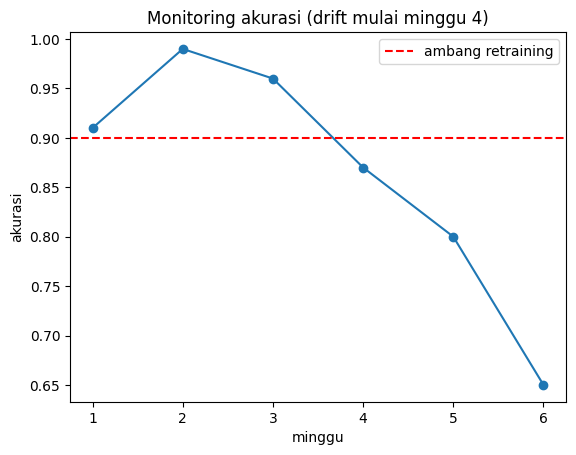

Perlu retraining pada minggu: [4, 5, 6]


In [6]:
acc_log = []
for week in range(1, 7):
    batch = Xte.sample(100, random_state=week, replace=True).copy(); drift = max(0, week - 3) * .10
    batch = batch * (1 + drift)          # simulasi pergeseran skala semua fitur (misal alat ukur diganti)
    acc_log.append(accuracy_score(yte.loc[batch.index], pipe.predict(batch)))
plt.plot(range(1, 7), acc_log, "o-"); plt.axhline(.90, ls="--", c="r", label="ambang retraining"); plt.legend()
plt.xlabel("minggu"); plt.ylabel("akurasi"); plt.title("Monitoring akurasi (drift mulai minggu 4)"); plt.show()
print("Perlu retraining pada minggu:", [w for w, a in zip(range(1, 7), acc_log) if a < .90])

Salah satu cara memperbarui model: **retrain penuh** dengan data baru, atau **pembelajaran inkremental** dengan `partial_fit`
untuk model yang mendukungnya (contoh: `SGDClassifier`).

In [7]:
sgd = SGDClassifier(loss="log_loss", random_state=0); sc = StandardScaler().fit(Xtr)
sgd.partial_fit(sc.transform(Xtr), ytr, classes=[0, 1]); print("Akurasi awal:", round(sgd.score(sc.transform(Xte), yte), 3))
sgd.partial_fit(sc.transform(Xte.iloc[:100]), yte.iloc[:100]); print("Setelah pembaruan inkremental:", round(sgd.score(sc.transform(Xte.iloc[100:]), yte.iloc[100:]), 3))

Akurasi awal: 0.936
Setelah pembaruan inkremental: 0.958


## 5. Mengelola Siklus Hidup Model
Setiap model yang di-deploy sebaiknya punya **versi** dan **metadata**: tanggal latih, versi library, metrik, serta ringkasan data latih.
Ini memudahkan audit, rollback bila model baru lebih buruk, dan reproduksi hasil. Alat yang umum: MLflow, DVC, model registry.

In [8]:
version = "v1.0.0"
meta = {"versi_model": version, "tanggal_latih": datetime.now().isoformat(timespec="seconds"), "sklearn": sklearn.__version__,
        "python": platform.python_version(), "fitur": list(X.columns), "metrik_uji": {"akurasi": round(pipe.score(Xte, yte), 4),
        "f1": round(f1_score(yte, pipe.predict(Xte)), 4)}, "n_data_latih": len(Xtr)}
joblib.dump(pipe, os.path.join(workdir, f"model_{version}.joblib"))
json.dump(meta, open(os.path.join(workdir, f"model_{version}.json"), "w"), indent=2)
print(json.dumps({k: meta[k] for k in ["versi_model", "sklearn", "metrik_uji"]}, indent=2))

{
  "versi_model": "v1.0.0",
  "sklearn": "1.8.0",
  "metrik_uji": {
    "akurasi": 0.9532,
    "f1": 0.963
  }
}


## 6. Menyiapkan Pipeline Deployment
Alur yang sehat: **latih → uji otomatis (batas performa minimum) → simpan versi baru → deploy → monitoring**.
Di bawah ini sebuah fungsi *quality gate*: model baru hanya dipromosikan jika tidak lebih buruk dari model yang sedang berjalan.
Berikutnya contoh kode untuk menyajikan model sebagai API (hanya sebagai contoh, tidak dijalankan di sini):

```python
# app.py  ->  jalankan: uvicorn app:app --reload
from fastapi import FastAPI
import joblib, pandas as pd
app = FastAPI(); model = joblib.load("model_v1.0.0.joblib")

@app.post("/predict")
def predict(rows: list[dict]):
    df = pd.DataFrame(rows)
    return {"prediction": model.predict(df).tolist(), "probability": model.predict_proba(df)[:, 1].round(4).tolist()}
```

In [9]:
def promote_if_better(new_model, current_path, Xv, yv, min_acc=.9, tolerance=.005):
    new_acc = accuracy_score(yv, new_model.predict(Xv)); cur_acc = accuracy_score(yv, joblib.load(current_path).predict(Xv))
    ok = new_acc >= min_acc and new_acc >= cur_acc - tolerance
    return ok, round(new_acc, 4), round(cur_acc, 4)

candidate = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
print("(promosi?, akurasi baru, akurasi model saat ini):", promote_if_better(candidate, os.path.join(workdir, f"model_{version}.joblib"), Xte, yte))

(promosi?, akurasi baru, akurasi model saat ini): (True, 0.9591, 0.9532)


## 7. Latihan Praktik

### Latihan 1 – Menyimpan dan Memuat Model untuk Deployment
Simulasikan layanan prediksi: muat model dari file, lalu prediksi satu data baru dalam bentuk dictionary (seperti dari request API).

In [10]:
service_model = joblib.load(os.path.join(workdir, f"model_{version}.joblib"))
request = Xte.iloc[[0]].to_dict(orient="records")
df_req = pd.DataFrame(request)[meta["fitur"]]            # pastikan urutan kolom sama dengan saat pelatihan
print("Prediksi:", int(service_model.predict(df_req)[0]), "| probabilitas kelas 1:", service_model.predict_proba(df_req)[0, 1].round(4))

Prediksi: 0 | probabilitas kelas 1: 0.005


### Latihan 2 – Memantau Performa Model
Hitung akurasi untuk beberapa batch data produksi dan beri peringatan bila di bawah ambang.

In [11]:
for i, start in enumerate(range(0, 150, 50), 1):
    b = Xte.iloc[start:start + 50]; a = accuracy_score(yte.iloc[start:start + 50], service_model.predict(b))
    print(f"Batch {i}: akurasi={a:.3f}", "OK" if a >= .9 else "PERINGATAN: periksa model / drift")

Batch 1: akurasi=0.940 OK
Batch 2: akurasi=0.960 OK
Batch 3: akurasi=0.940 OK


### Latihan 3 – Memeriksa Drift Data
Gunakan uji KS untuk membandingkan satu fitur antara data latih dan data produksi simulasi.

In [12]:
stat, p = ks_2samp(Xtr["mean radius"], shifted["mean radius"]); print(f"KS={stat:.3f}, p-value={p:.2e} ->", "ada drift" if p < .01 else "tidak ada drift")

KS=0.531, p-value=9.56e-29 ->

 ada drift


**Kesimpulan:** deployment bukan akhir proyek. Simpan seluruh pipeline beserta versi dan metadatanya, pantau data dan performa secara
berkala, dan siapkan mekanisme retraining serta rollback.